# Sesión 8 · Clasificación II: Naive Bayes y K-Vecinos Más Cercanos (KNN)

> **Minería de Datos · UNIMINUTO Ibagué · 2026-2**  
> Docente: Esteban Ernesto Morales Castro  
> Proyecto: **AUTOGEST** — Análisis de Siniestralidad Vial en Ibagué

---

## Objetivos de la sesión
1. **Aplicar** el Teorema de Bayes e implementar `GaussianNB`.
2. **Entrenar** `KNeighborsClassifier` dentro de un `Pipeline` con `StandardScaler`.
3. **Justificar** por qué KNN exige escalar («distancia manda a escalar»).
4. **Comparar** Árbol de Decisión, Naive Bayes y KNN y emitir un veredicto técnico.

---

**Recordatorio crítico de laboratorio:**  
Los tres modelos usan **la misma partición** (75/25 estratificada, `random_state=42`).  
Sin esa equidad, la comparación no tiene valor alguno.

## 0 · Configuración del entorno

In [1]:
# ── Ruta de trabajo ──────────────────────────────────────────────────────────
import sys
from pathlib import Path

# Asegura que el directorio raíz del proyecto esté en el path
raiz = Path.cwd().parent if Path.cwd().name == "analisis" else Path.cwd()
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

print("Raíz del proyecto:", raiz)

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 20)
print("Entorno listo ✓")

Raíz del proyecto: c:\Users\Gilary Gacha\Desktop\autogest
Entorno listo ✓


## 1 · Carga del módulo ClasificacionModelos

In [3]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Gilary Gacha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [4]:
from src.clasificacion_modelos import ClasificacionModelos

# Instanciar apuntando al dataset integrado del proyecto AUTOGEST
cm = ClasificacionModelos(ruta="dataset/dataset_integrado.csv")
df = cm.cargar()

print(f"Dataset AUTOGEST cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Variable objetivo: {cm.OBJETIVO}")
print(f"Features numéricas ({len(cm.NUMERICAS)}): {cm.NUMERICAS}")
df.head(3)

Dataset AUTOGEST cargado: 507 filas × 18 columnas
Variable objetivo: ACCIDENTES_REGISTRADOS
Features numéricas (8): ['AÑO', 'MES', 'VOLUMEN_TRAFICO', 'VEHICULOS_EVASORES', 'VEHICULOS_EXENTOS', 'SERVICIOS_TALLER', 'COSTO_TOTAL_TALLER', 'MILLAJE_PROMEDIO']


,AÑO,MES,TIPO_VEHICULO,VOLUMEN_TRAFICO,VEHICULOS_EVASORES,VEHICULOS_EXENTOS,TARIFA_PROMEDIO,RECAUDO_PEAJES,SERVICIOS_TALLER,COSTO_TOTAL_TALLER,COSTO_PROMEDIO_TALLER,HORAS_SERVICIO_PROMEDIO,MILLAJE_PROMEDIO,DISTANCIA_GRUA_TOTAL,ACCIDENTES_TOTALES,ACCIDENTES_REGISTRADOS,TASA_EVASION_PCT,TASA_EXENCION_PCT
0,2014,1,CARGA_PESADO,3135469.0000,2.0000,10689.0000,19007.5975,72257688200.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3012,468.0000,0.0001,0.3409
1,2014,1,LIVIANO,13980059.0000,30.0000,132797.0000,5628.1955,95583080700.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3012,2085.0000,0.0002,0.9499
2,2014,1,TRANSPORTE_PASAJEROS,3078197.0000,0.0000,17881.0000,7236.2963,25178677200.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3012,459.0000,0.0000,0.5809


## 2 · Tablero compartido (Código 1 de la demo)

Preparamos **X** (features) e **y** (target discretizado) y realizamos el  
split **único** estratificado que usarán los 3 modelos.

In [5]:
# test_size=0.25  →  75 % train / 25 % test  (estratificado, seed=42)
cm.preparar_datos(n_clases=3, test_size=0.25, random_state=42)

print(f"X_train: {cm.X_train.shape}")
print(f"X_test : {cm.X_test.shape}")
print()
print("Distribución de clases en train:")
print(cm.y_train.value_counts(normalize=True).round(3))
print()
print("Distribución de clases en test:")
print(cm.y_test.value_counts(normalize=True).round(3))
print()
print(f"Features del modelo ({len(cm.feature_names)}):")
print(cm.feature_names)

X_train: (380, 12)
X_test : (127, 12)

Distribución de clases en train:
Medio   0.3370
Alto    0.3340
Bajo    0.3290
Name: proportion, dtype: float64

Distribución de clases en test:
Medio   0.3390
Bajo    0.3310
Alto    0.3310
Name: proportion, dtype: float64

Features del modelo (12):
['AÑO', 'MES', 'VOLUMEN_TRAFICO', 'VEHICULOS_EVASORES', 'VEHICULOS_EXENTOS', 'SERVICIOS_TALLER', 'COSTO_TOTAL_TALLER', 'MILLAJE_PROMEDIO', 'TIPO_VEHICULO_CARGA_PESADO', 'TIPO_VEHICULO_LIVIANO', 'TIPO_VEHICULO_OTRO', 'TIPO_VEHICULO_TRANSPORTE_PASAJEROS']


## 3 · Torneo de los tres modelos (Código 2 de la demo)

| Modelo | Escala? | Tipo |
|---|---|---|
| Árbol de Decisión (prof=4) | No necesita | Eager |
| GaussianNB | No necesita | Eager |
| KNN k=5 (escalado) | **SÍ, crítico** | Lazy |

In [6]:
tabla_torneo = cm.torneo(verbose=True)
tabla_torneo


────────────────────────────────────────────────────────────
       TORNEO DE CLASIFICACIÓN · AUTOGEST · Sesión 8        
────────────────────────────────────────────────────────────
Modelo                      fit(s)  acc_train   acc_test
────────────────────────────────────────────────────────────
Árbol (prof=4)              0.0074      0.889      0.835
Naive Bayes                 0.0065      0.603      0.598
KNN (k=5) escalado          0.0066      0.916      0.835
────────────────────────────────────────────────────────────

[Nota] KNN sin escalar → ver self.efecto_escalado_knn()



,Modelo,fit_s,acc_train,acc_test,acc_train_%,acc_test_%
0,Árbol (prof=4),0.0074,0.8895,0.8346,88.95%,83.46%
1,Naive Bayes,0.0065,0.6026,0.5984,60.26%,59.84%
2,KNN (k=5) escalado,0.0066,0.9158,0.8346,91.58%,83.46%


## 4 · Exploración del parámetro k (Paso 3 del taller)

> **Regla:** k=1 memoriza → sobreajuste; k muy grande → subajuste.  
> Busque el **equilibrio** observando la brecha train–test.

In [7]:
# Valores obligatorios del taller: k = 1, 11, 51
# Se añaden 5 y 31 para visualizar la curva completa
tabla_k = cm.explorar_k(valores_k=[1, 5, 11, 31, 51], verbose=True)
tabla_k


──────────────────────────────────────────────────────────────
          EXPLORACIÓN DEL PARÁMETRO k · KNN escalado          
──────────────────────────────────────────────────────────────
    k    acc_train   acc_test  Diagnóstico
──────────────────────────────────────────────────────────────
    1        1.000      0.850  Memoriza cada punto → sobreajuste evidente
    5        0.916      0.835  Buen equilibrio bias-varianza
   11        0.847      0.850  Estable, buena generalización
   31        0.753      0.811  Vecindario amplio, suaviza fronteras
   51        0.726      0.795  Consulta ~10% de los datos → subajuste suave
──────────────────────────────────────────────────────────────



,k,acc_train,acc_test,Diagnóstico
0,1,1.0000,0.8504,Memoriza cada punto → sobreajuste evidente
1,5,0.9158,0.8346,Buen equilibrio bias-varianza
2,11,0.8474,0.8504,"Estable, buena generalización"
3,31,0.7526,0.8110,"Vecindario amplio, suaviza fronteras"
4,51,0.7263,0.7953,Consulta ~10% de los datos → subajuste suave


## 5 · Efecto del escalado en KNN

Demuestra por qué **"distancia manda a escalar"** (Sesión 8, diapositiva 12).

In [8]:
resultado_escala = cm.efecto_escalado_knn(k=5)
resultado_escala


── Efecto del escalado en KNN (k=5) ──────────────────
  Sin StandardScaler : acc_test = 0.740
  Con StandardScaler : acc_test = 0.835
  Diferencia         : +0.095
  → 'distancia manda a escalar' ✓
────────────────────────────────────────────────────────


{'sin_escalar': 0.7402, 'escalado': 0.8346, 'diferencia': 0.0945}

## 6 · Reportes detallados por modelo

Matriz de confusión + precision / recall / f1 de cada clasificador.

In [9]:
for nombre in cm.modelos.keys():
    rep = cm.reporte_modelo(nombre)
    print(f"\n{'═'*55}")
    print(f"  {nombre}")
    print(f"{'═'*55}")
    print("\nMatriz de Confusión:")
    display(rep["confusion_matrix"])
    print("\nReporte de Clasificación:")
    display(rep["report"])


═══════════════════════════════════════════════════════
  Árbol (prof=4)
═══════════════════════════════════════════════════════

Matriz de Confusión:


,Pred_Alto,Pred_Bajo,Pred_Medio
Real_Alto,39,0,3
Real_Bajo,0,42,0
Real_Medio,5,13,25



Reporte de Clasificación:


,precision,recall,f1-score,support
Alto,0.8864,0.9286,0.9070,42.0000
Bajo,0.7636,1.0000,0.8660,42.0000
Medio,0.8929,0.5814,0.7042,43.0000
accuracy,0.8346,0.8346,0.8346,0.8346
macro avg,0.8476,0.8367,0.8257,127.0000
weighted avg,0.8480,0.8346,0.8248,127.0000



═══════════════════════════════════════════════════════
  Naive Bayes
═══════════════════════════════════════════════════════

Matriz de Confusión:


,Pred_Alto,Pred_Bajo,Pred_Medio
Real_Alto,33,6,3
Real_Bajo,0,42,0
Real_Medio,2,40,1


... (2 outputs left out)


═══════════════════════════════════════════════════════
  KNN (k=5) escalado
═══════════════════════════════════════════════════════

Matriz de Confusión:


,Pred_Alto,Pred_Bajo,Pred_Medio
Real_Alto,38,0,4
Real_Bajo,0,39,3
Real_Medio,9,5,29



Reporte de Clasificación:


,precision,recall,f1-score,support
Alto,0.8085,0.9048,0.8539,42.0000
Bajo,0.8864,0.9286,0.9070,42.0000
Medio,0.8056,0.6744,0.7342,43.0000
accuracy,0.8346,0.8346,0.8346,0.8346
macro avg,0.8335,0.8359,0.8317,127.0000
weighted avg,0.8333,0.8346,0.8309,127.0000


## 7 · Generación de figuras diagnósticas

Genera en `analisis/figuras/`:
- `fig_torneo_accuracy_comparado.png`
- `fig_knn_efecto_k.png`
- `fig_knn_efecto_escalado.png`
- `fig_matrices_confusion_sesion8.png`

[OK] fig_torneo_accuracy_comparado.png
[OK] fig_knn_efecto_k.png

── Efecto del escalado en KNN (k=5) ──────────────────
  Sin StandardScaler : acc_test = 0.740
  Con StandardScaler : acc_test = 0.835
  Diferencia         : +0.095
  → 'distancia manda a escalar' ✓
────────────────────────────────────────────────────────
[OK] fig_knn_efecto_escalado.png
[OK] fig_matrices_confusion_sesion8.png

[OK] Figuras de la Sesión 8 guardadas en: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras

── fig_torneo ──


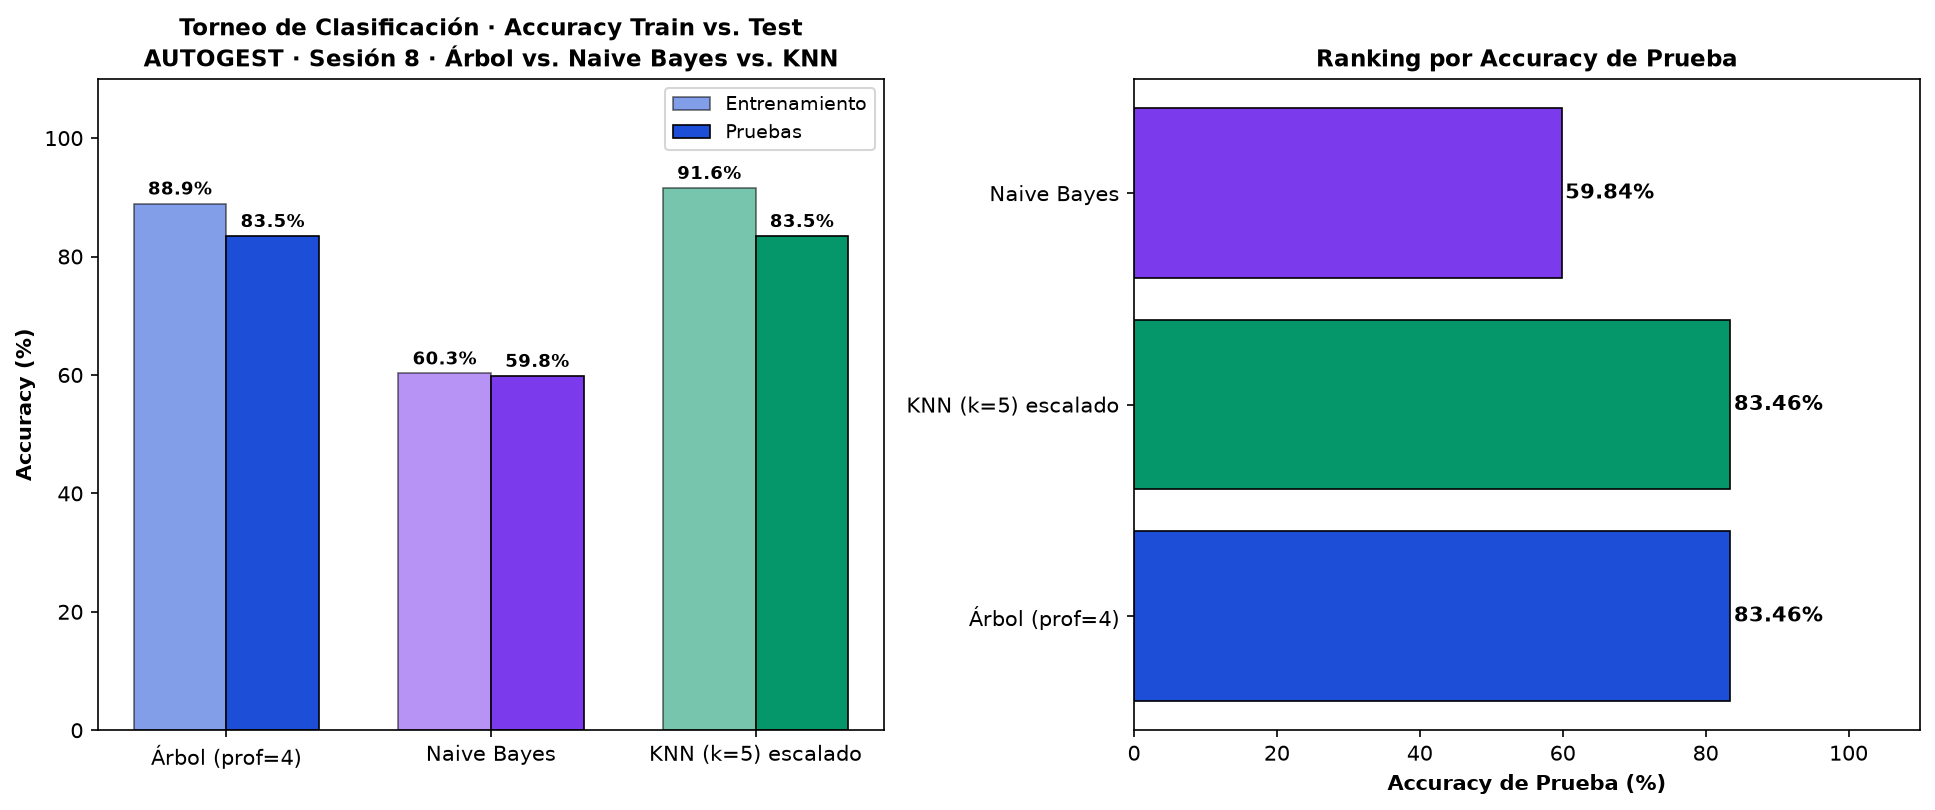


── fig_knn_efecto_k ──


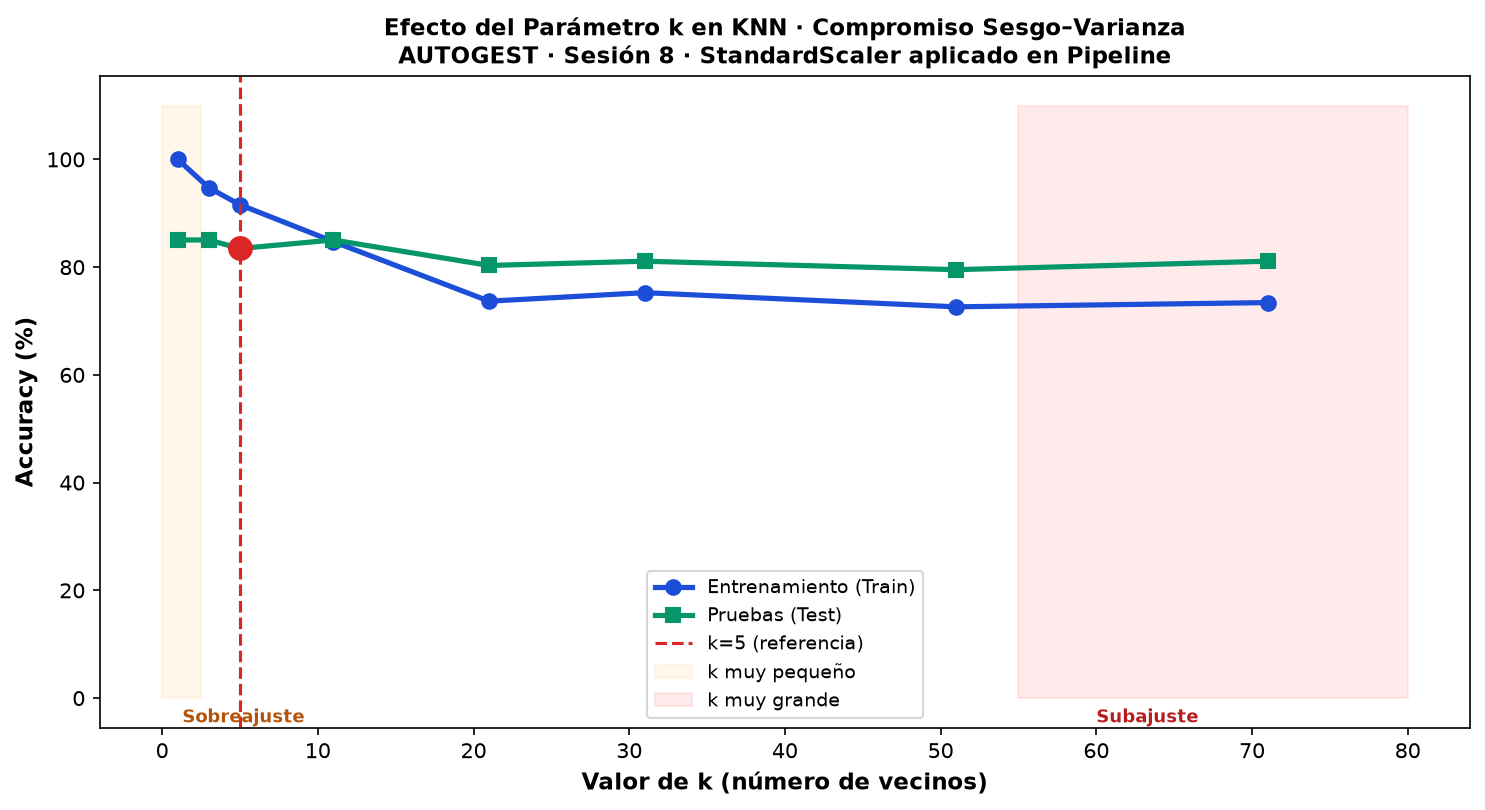


── fig_knn_efecto_escalado ──


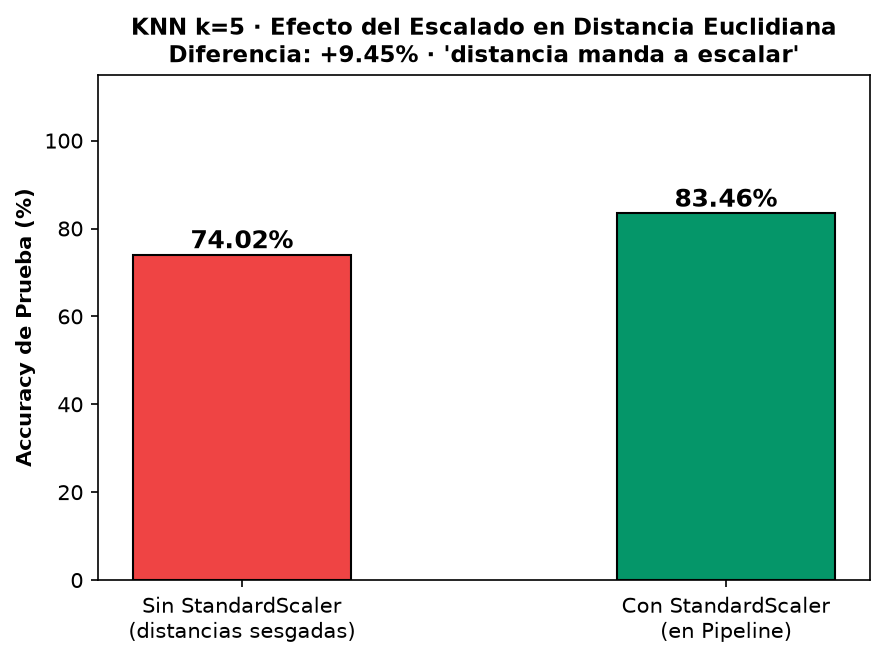


── fig_matrices_confusion ──


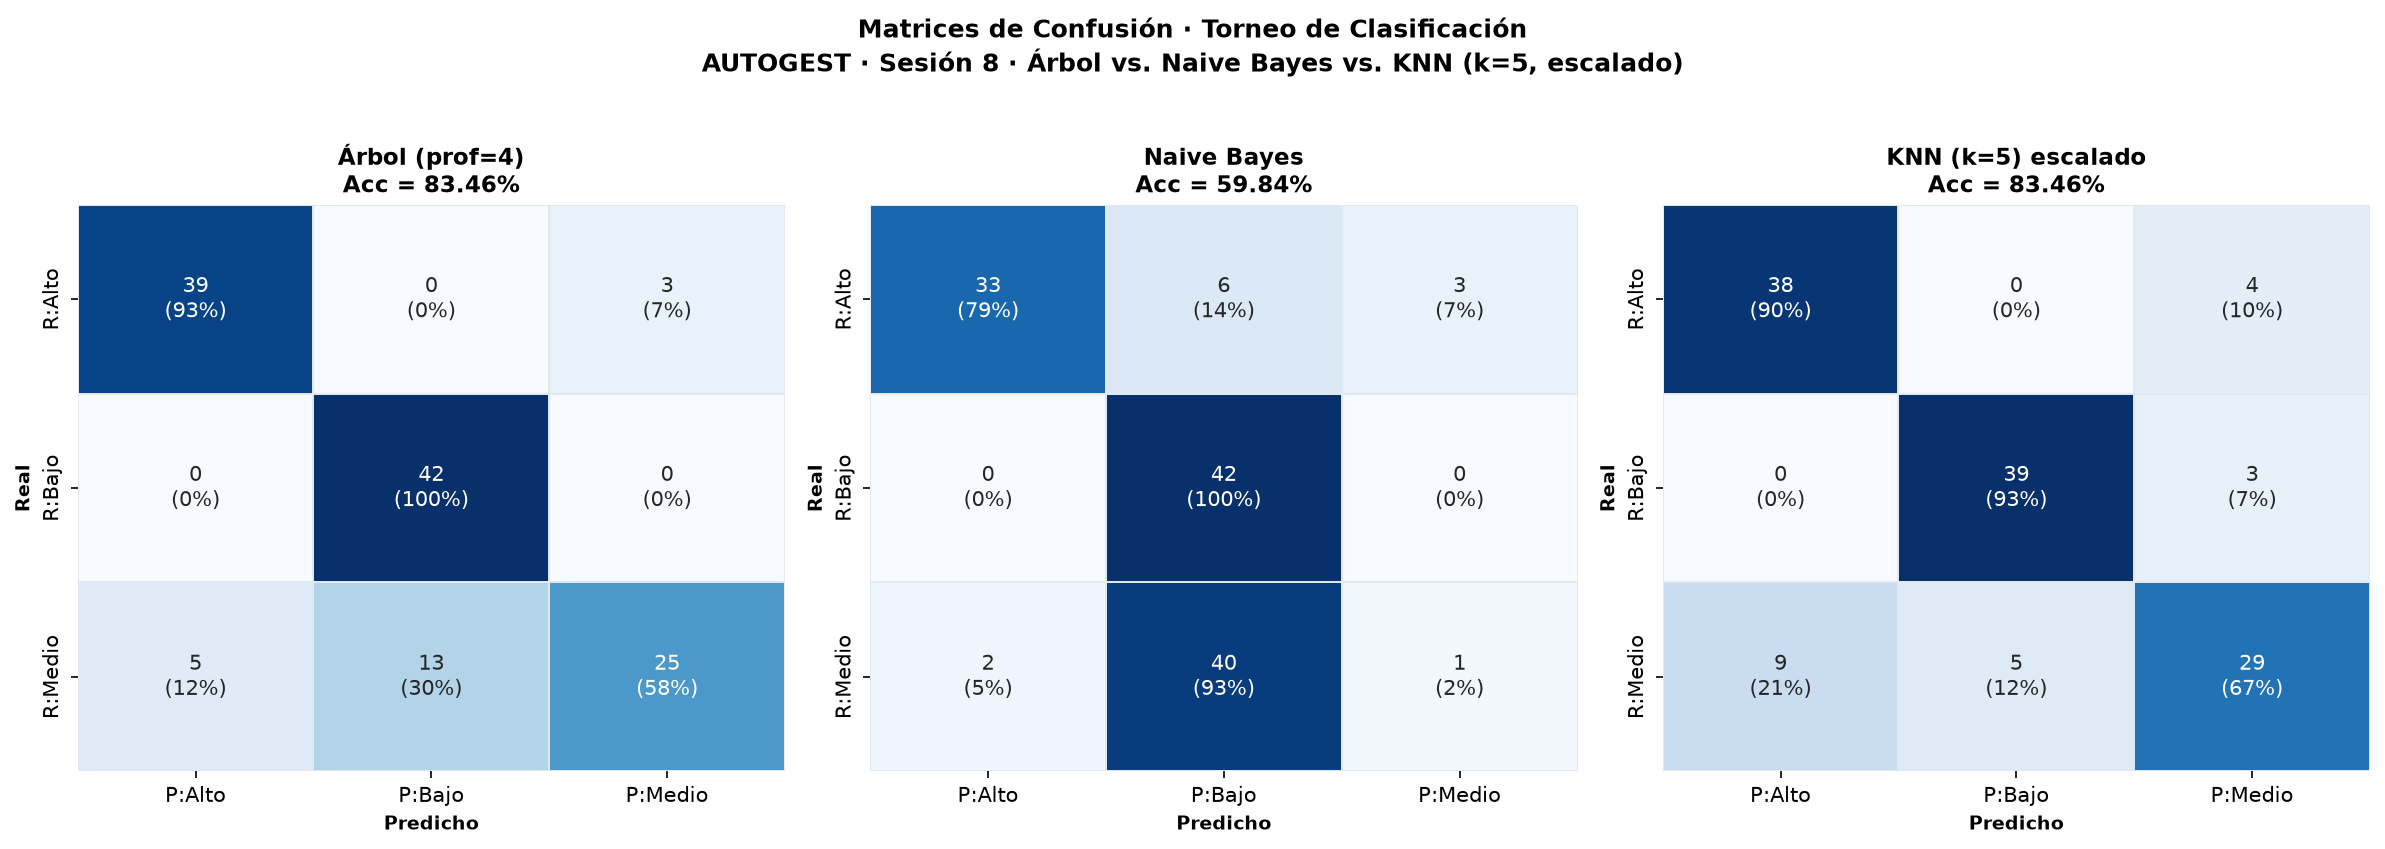

In [10]:
rutas = cm.generar_figuras(carpeta_salida="analisis/figuras")

# Mostrar las figuras en el notebook
from IPython.display import Image, display as ipy_display

for nombre_fig, ruta_fig in rutas.items():
    print(f"\n── {nombre_fig} ──")
    ipy_display(Image(filename=ruta_fig, width=820))

## 8 · Pista técnica: variar k dentro del Pipeline

Reproducción exacta del snippet de la diapositiva 18 de la presentación.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier())

print(f"{'k':>4}  acc_test")
print("-" * 15)
for k in [1, 11, 51]:
    knn.set_params(kneighborsclassifier__n_neighbors=k)
    knn.fit(cm.X_train, cm.y_train)
    acc = round(knn.score(cm.X_test, cm.y_test), 3)
    print(f"{k:>4}  {acc}")

   k  acc_test
---------------
   1  0.85
  11  0.85
  51  0.795


## 9 · Veredicto técnico (Paso 4 del taller)

Recomendación justificada con múltiples criterios y lenguaje de negocio.

In [12]:
veredicto = cm.veredicto_tecnico()

══════════════════════════════════════════════════════════════
VEREDICTO TÉCNICO · AUTOGEST · Torneo de Clasificación
Sesión 8 · Minería de Datos · UNIMINUTO Ibagué · 2026-2
══════════════════════════════════════════════════════════════

Modelo                     acc_train   acc_test
──────────────────────────────────────────────────
Árbol (prof=4)                 0.889      0.835
KNN (k=5) escalado             0.916      0.835
Naive Bayes                    0.603      0.598

► Ganador en accuracy de prueba: Árbol (prof=4) (83.46%)

RECOMENDACIÓN PARA AUTOGEST:
  • Árbol de Decisión (prof=4): modelo PRINCIPAL para producción.
    Ofrece reglas IF-THEN legibles para inspectores y directivos viales,
    requisito crítico en gestión pública de siniestralidad.
  • Naive Bayes: línea base permanente. Reentrenar diario es trivial;
    si NB supera al árbol, el problema se simplificó o hay fuga de datos.
  • KNN (k=5 escalado): útil para análisis exploratorio local,
    pero lento en predicc

---

## Checklist del taller práctico

| # | Requisito | ¿Cumplido? |
|---|---|---|
| 1 | X/y con `get_dummies`, split `test_size=0.25`, `random_state=42`, `stratify=y` | ✅ Sección 2 |
| 2 | 3 rivales: árbol prof=4, GaussianNB, Pipeline escalador+KNN k=5 | ✅ Sección 3 |
| 3 | Tabla accuracy train/test + tiempo de fit | ✅ Sección 3 |
| 4 | Exploración k=1, 11, 51 con lectura de sobre/subajuste | ✅ Sección 4 |
| 5 | Veredicto escrito (accuracy + interpretabilidad + costos) | ✅ Sección 9 |
| 6 | KNN siempre dentro de Pipeline (nunca escala datos de test) | ✅ Pipeline usado |
| 7 | Figuras exportadas en alta resolución | ✅ Sección 7 |

---

**Anticipo Sesión 9 — Clustering (K-means):** aprendizaje NO supervisado.  
Se apagarán las etiquetas: K-means descubrirá segmentos naturales de períodos
de tráfico en Ibagué y los perfilaremos operacionalmente.

---
*AUTOGEST · Ingeniería de Sistemas · UNIMINUTO Ibagué · 2026-2*